In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/deepakorani/Supermarket-Sales-Kaggle-Dataset/main/supermarket_sales.csv"

df = pd.read_csv(url)

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()



First five rows:


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3



Dataset shape: (1000, 17)

Column names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Missing values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------

In [3]:

# Step 2: Data Cleaning and Preparation

# 1. Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# 2. Remove duplicate rows if any
df = df.drop_duplicates()

# 3. Convert Date column to datetime
df["Date"] = pd.to_datetime(
    df["Date"], format="%m/%d/%Y", errors="coerce"
)

# 4. Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("%", "percent", regex=False)
)

# 5. Check data types and missing values
print("\nDataset shape after cleaning:", df.shape)

print("\nColumn names after cleaning:")
print(df.columns.tolist())

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

# 6. Display cleaned data
display(df.head())


Number of duplicate rows: 0

Dataset shape after cleaning: (1000, 17)

Column names after cleaning:
['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5percent', 'total', 'date', 'time', 'payment', 'cogs', 'gross_margin_percentage', 'gross_income', 'rating']

Missing values after cleaning:
invoice_id                 0
branch                     0
city                       0
customer_type              0
gender                     0
product_line               0
unit_price                 0
quantity                   0
tax_5percent               0
total                      0
date                       0
time                       0
payment                    0
cogs                       0
gross_margin_percentage    0
gross_income               0
rating                     0
dtype: int64

Date range:
2019-01-01 00:00:00 to 2019-03-30 00:00:00


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5percent,total,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [4]:

# Step 3: Validate the cleaned dataset

print("Second row:")
display(df.iloc[[1]])

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nSales summary:")
print(df[["unit_price", "quantity", "total", "gross_income"]].describe())



Second row:


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5percent,total,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.82,80.22,2019-03-08,10:29,Cash,76.4,4.761905,3.82,9.6



Missing values: 0
Duplicate rows: 0

Sales summary:
        unit_price     quantity        total  gross_income
count  1000.000000  1000.000000  1000.000000   1000.000000
mean     55.672130     5.510000   322.966749     15.379369
std      26.494628     2.923431   245.885335     11.708825
min      10.080000     1.000000    10.678500      0.508500
25%      32.875000     3.000000   124.422375      5.924875
50%      55.230000     5.000000   253.848000     12.088000
75%      77.935000     8.000000   471.350250     22.445250
max      99.960000    10.000000  1042.650000     49.650000


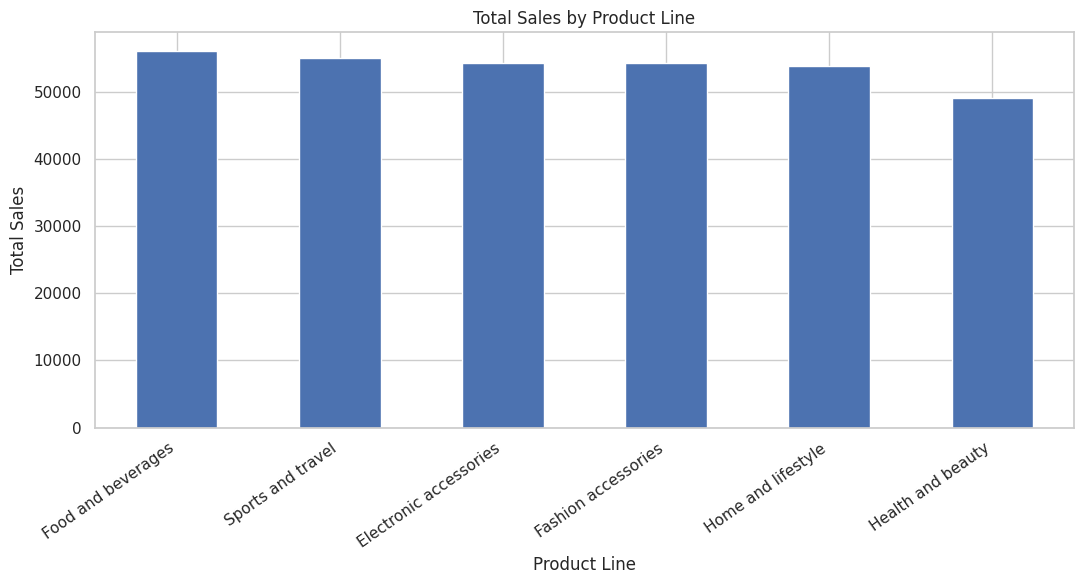

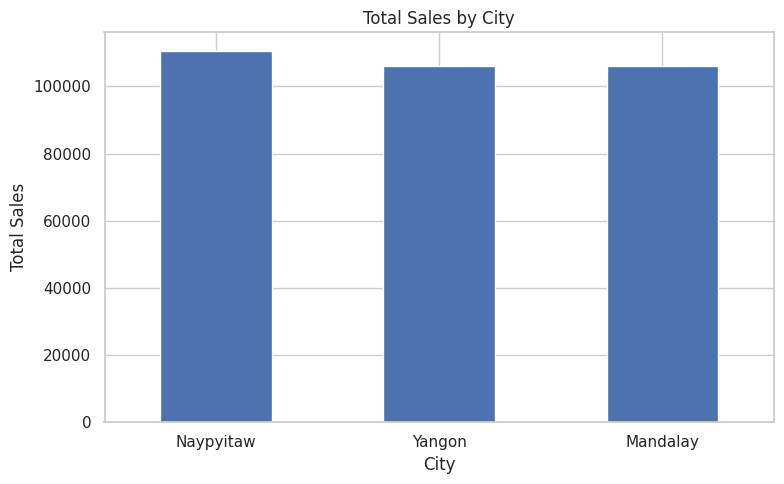

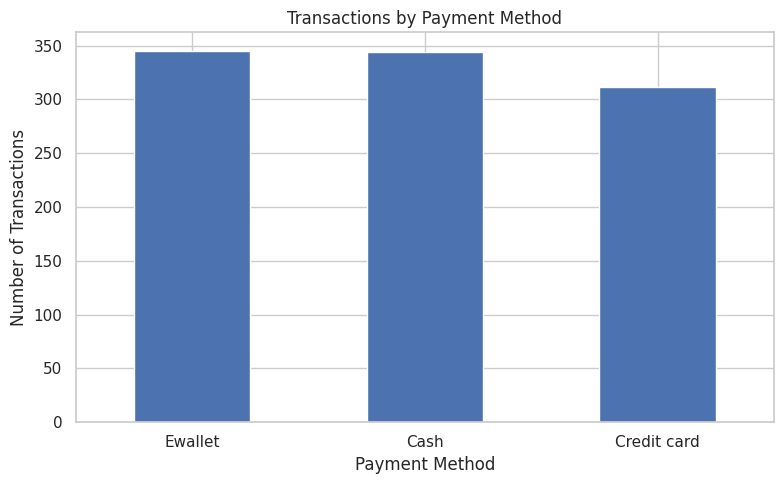

Total revenue: 322966.75

Sales by product line:
product_line
Food and beverages        56144.84
Sports and travel         55122.83
Electronic accessories    54337.53
Fashion accessories       54305.90
Home and lifestyle        53861.91
Health and beauty         49193.74
Name: total, dtype: float64

Sales by city:
city
Naypyitaw    110568.71
Yangon       106200.37
Mandalay     106197.67
Name: total, dtype: float64

Transactions by payment method:
payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


In [5]:

# Step 4: Exploratory Data Analysis and Visualization

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Total sales by product line
sales_by_product = (
    df.groupby("product_line")["total"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))
sales_by_product.plot(kind="bar")
plt.title("Total Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# 2. Total sales by city
sales_by_city = (
    df.groupby("city")["total"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sales_by_city.plot(kind="bar")
plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Number of transactions by payment method
payment_counts = df["payment"].value_counts()

plt.figure(figsize=(8, 5))
payment_counts.plot(kind="bar")
plt.title("Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Summary of key results
print("Total revenue:", round(df["total"].sum(), 2))
print("\nSales by product line:")
print(sales_by_product.round(2))

print("\nSales by city:")
print(sales_by_city.round(2))

print("\nTransactions by payment method:")
print(payment_counts)



## Key Findings

The sales dataset contains 1,000 transactions recorded between January and March 2019.

The dataset was checked for missing values and duplicate records. No missing values or duplicate rows were found.

The analysis explores sales performance across product lines and cities, as well as customer payment preferences. Bar charts were used to compare total sales and transaction counts.

These findings help identify differences in sales performance and customer payment behavior.

## Tools and Technologies

- Python
- Pandas
- Matplotlib
- Seaborn
- Google Colab

## Conclusion

This project demonstrates the use of Python for data cleaning, exploratory data analysis, and data visualization. It provides an overview of supermarket sales and shows how data analysis can support business decision-making.